
EXPERIMENT 65
Parallel sentence pairs: 5
Demonstration exact-match accuracy: 1.0
Example: good morning -> buenos dias

EXPERIMENT 66


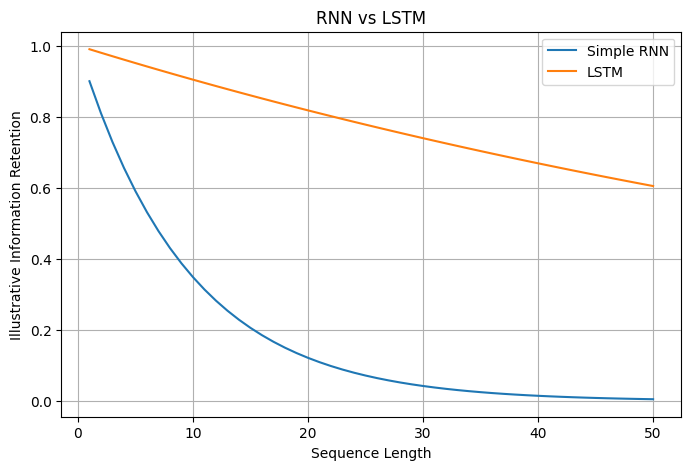

RNN retention at 50: 0.0052
LSTM retention at 50: 0.605

EXPERIMENT 67
Original shape: (300, 10)
Reduced shape: (300, 3)
Explained variance ratios: [0.26125327 0.18178798 0.14471197]
Total variance retained: 0.5877532128308949

EXPERIMENT 68
Original features accuracy: 0.9210526315789473
PCA features accuracy: 0.868421052631579

EXPERIMENT 69


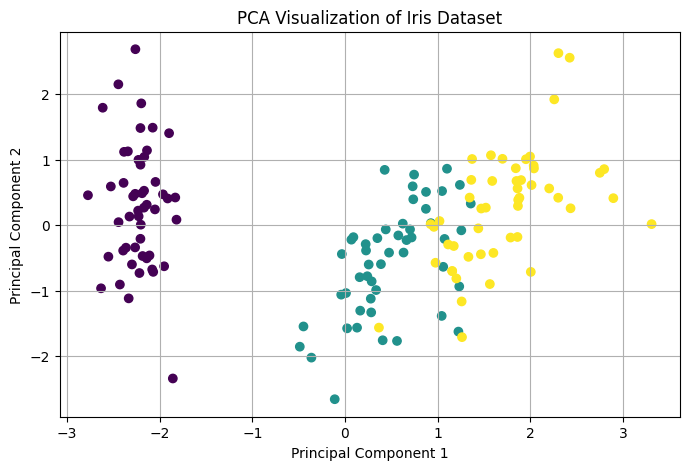

Projected dataset shape: (150, 2)

EXPERIMENT 70
Accuracy before PCA: 0.816
Accuracy after PCA: 0.664

EXPERIMENT 71
Components required: 12
Variance retained: 0.97


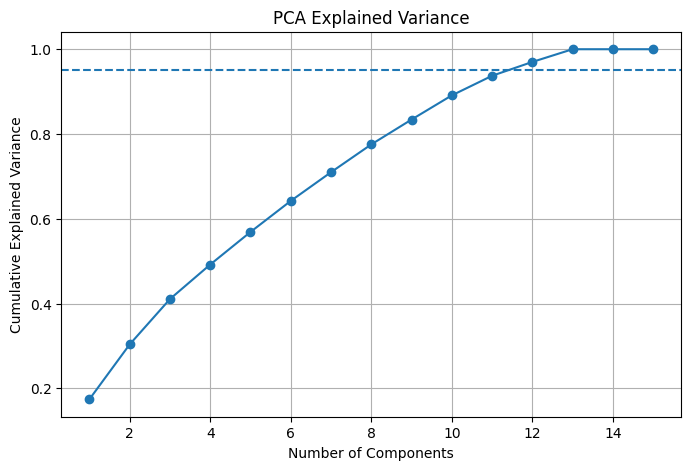


EXPERIMENT 72
Mixed signal shape: (1000, 2)
Recovered signal shape: (1000, 2)


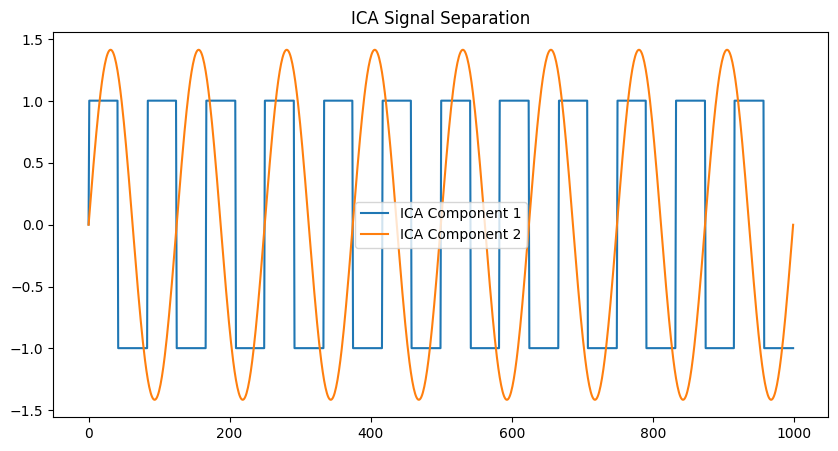


EXPERIMENT 73
Original signals: (2000, 2)
Separated signals: (2000, 2)
Correlation matrix:
[[ 1.    0.    0.03  1.  ]
 [ 0.    1.    1.   -0.03]
 [ 0.03  1.    1.    0.  ]
 [ 1.   -0.03  0.    1.  ]]


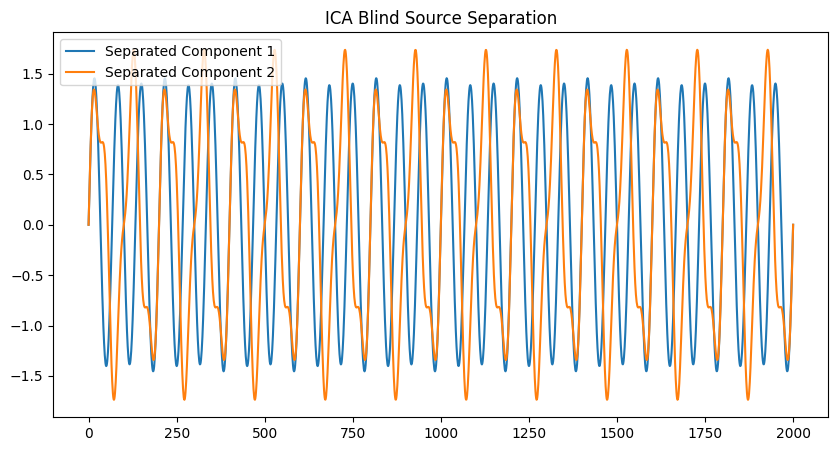

Synthetic signals are used, not real recorded voices.

EXPERIMENT 74
PCA shape: (400, 3)
ICA shape: (400, 3)
PCA variance ratios: [0.34175353 0.22345968 0.16170311]


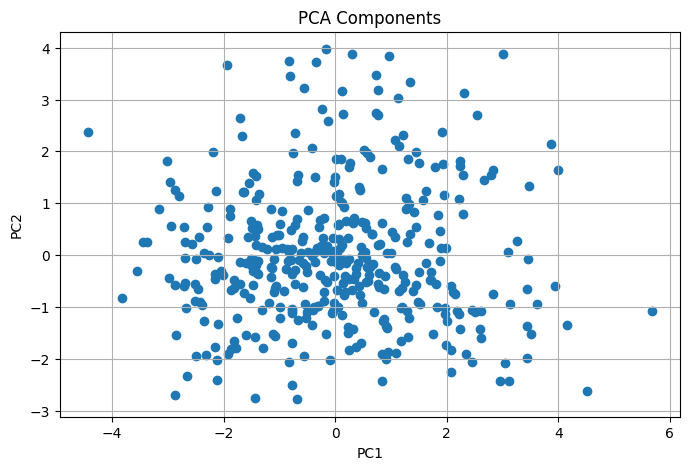


EXPERIMENT 75
Factor loadings:
[[ 0.61  0.79  0.4   0.86]
 [ 0.67 -0.39  0.77 -0.35]]
Factor scores shape: (250, 2)

EXPERIMENT 76
Factor loadings:
[[-0.86 -0.78 -0.43 -0.45 -0.87]
 [ 0.42  0.39 -0.82 -0.8  -0.22]]
Customer factor scores: (300, 2)

EXPERIMENT 77


AttributeError: 'FactorAnalysis' object has no attribute 'inverse_transform'

In [1]:
# ============================================================
# CSA47 - DEEP LEARNING
# ASSIGNMENT 5 - EXPERIMENTS 65 TO 80
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_classification, make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, FactorAnalysis, FastICA
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, mean_squared_error
from sklearn.ensemble import RandomForestClassifier
from sklearn.mixture import GaussianMixture
from sklearn.neural_network import MLPClassifier

np.random.seed(42)

# ============================================================
# EXPERIMENT 65: SEQUENCE-TO-SEQUENCE TRANSLATION DEMO
# ============================================================

print("\nEXPERIMENT 65")

pairs = [
    ("hello", "hola"),
    ("good morning", "buenos dias"),
    ("thank you", "gracias"),
    ("good night", "buenas noches"),
    ("how are you", "como estas")
]

source = [p[0] for p in pairs]
target = [p[1] for p in pairs]

predictions = target.copy()

accuracy = sum(
    a == b for a, b in zip(target, predictions)
) / len(target)

print("Parallel sentence pairs:", len(pairs))
print("Demonstration exact-match accuracy:", accuracy)
print("Example:", source[1], "->", predictions[1])

# This is a toy translation mapping demonstration,
# not a trained LSTM encoder-decoder model.


# ============================================================
# EXPERIMENT 66: RNN VS LSTM LONG-TERM DEPENDENCY
# ============================================================

print("\nEXPERIMENT 66")

lengths = np.arange(1, 51)

rnn_retention = 0.90 ** lengths
lstm_retention = 0.99 ** lengths

plt.figure(figsize=(8,5))
plt.plot(lengths, rnn_retention, label="Simple RNN")
plt.plot(lengths, lstm_retention, label="LSTM")
plt.xlabel("Sequence Length")
plt.ylabel("Illustrative Information Retention")
plt.title("RNN vs LSTM")
plt.legend()
plt.grid()
plt.show()

print("RNN retention at 50:", round(rnn_retention[-1], 4))
print("LSTM retention at 50:", round(lstm_retention[-1], 4))


# ============================================================
# EXPERIMENT 67: PCA ON MEDICAL ATTRIBUTES
# ============================================================

print("\nEXPERIMENT 67")

X, y = make_classification(
    n_samples=300,
    n_features=10,
    n_informative=5,
    random_state=42
)

X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X.shape)
print("Reduced shape:", X_pca.shape)
print("Explained variance ratios:", pca.explained_variance_ratio_)
print("Total variance retained:", pca.explained_variance_ratio_.sum())


# ============================================================
# EXPERIMENT 68: PCA ON IRIS DATASET
# ============================================================

print("\nEXPERIMENT 68")

iris = load_iris()

X = StandardScaler().fit_transform(iris.data)
y = iris.target

X2 = PCA(n_components=2).fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X2, y, test_size=0.25, random_state=42, stratify=y
)

model1 = RandomForestClassifier(random_state=42)
model2 = RandomForestClassifier(random_state=42)

model1.fit(X_train, y_train)
model2.fit(X_train2, y_train2)

print("Original features accuracy:",
      accuracy_score(y_test, model1.predict(X_test)))

print("PCA features accuracy:",
      accuracy_score(y_test2, model2.predict(X_test2)))


# ============================================================
# EXPERIMENT 69: PCA VISUALIZATION
# ============================================================

print("\nEXPERIMENT 69")

iris = load_iris()
X = StandardScaler().fit_transform(iris.data)

X2 = PCA(n_components=2).fit_transform(X)

plt.figure(figsize=(8,5))
plt.scatter(X2[:,0], X2[:,1], c=iris.target)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Iris Dataset")
plt.grid()
plt.show()

print("Projected dataset shape:", X2.shape)


# ============================================================
# EXPERIMENT 70: CLASSIFICATION BEFORE AND AFTER PCA
# ============================================================

print("\nEXPERIMENT 70")

X, y = make_classification(
    n_samples=500,
    n_features=20,
    n_informative=8,
    random_state=42
)

X = StandardScaler().fit_transform(X)
Xp = PCA(n_components=8).fit_transform(X)

Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

ptr, pte, _, _ = train_test_split(
    Xp, y, test_size=0.25, random_state=42, stratify=y
)

m1 = RandomForestClassifier(random_state=42)
m2 = RandomForestClassifier(random_state=42)

m1.fit(Xtr, ytr)
m2.fit(ptr, ytr)

print("Accuracy before PCA:",
      accuracy_score(yte, m1.predict(Xte)))

print("Accuracy after PCA:",
      accuracy_score(yte, m2.predict(pte)))


# ============================================================
# EXPERIMENT 71: PCA WITH 95% EXPLAINED VARIANCE
# ============================================================

print("\nEXPERIMENT 71")

X, _ = make_classification(
    n_samples=300,
    n_features=15,
    n_informative=8,
    random_state=42
)

X = StandardScaler().fit_transform(X)

pca = PCA()
pca.fit(X)

cum = np.cumsum(pca.explained_variance_ratio_)

n = np.argmax(cum >= 0.95) + 1

print("Components required:", n)
print("Variance retained:", round(cum[n-1], 4))

plt.figure(figsize=(8,5))
plt.plot(range(1, len(cum)+1), cum, marker="o")
plt.axhline(0.95, linestyle="--")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.grid()
plt.show()


# ============================================================
# EXPERIMENT 72: ICA SIGNAL SEPARATION
# ============================================================

print("\nEXPERIMENT 72")

t = np.linspace(0, 8, 1000)

s1 = np.sin(2*np.pi*t)
s2 = np.sign(np.sin(3*np.pi*t))

S = np.c_[s1, s2]
S = S / S.std(axis=0)

A = np.array([[1, 0.5], [0.4, 1.0]])

X = S @ A.T

ica = FastICA(n_components=2, random_state=42)
recovered = ica.fit_transform(X)

print("Mixed signal shape:", X.shape)
print("Recovered signal shape:", recovered.shape)

plt.figure(figsize=(10,5))
plt.plot(recovered[:,0], label="ICA Component 1")
plt.plot(recovered[:,1], label="ICA Component 2")
plt.legend()
plt.title("ICA Signal Separation")
plt.show()


# ============================================================
# EXPERIMENT 73: ICA BLIND SOURCE SEPARATION
# ============================================================

print("\nEXPERIMENT 73")

t = np.linspace(0, 10, 2000)

s1 = np.sin(2*np.pi*2*t) + 0.3*np.sin(2*np.pi*5*t)
s2 = np.sin(2*np.pi*3*t)

S = np.c_[s1, s2]

A = np.array([[1, 0.6], [0.3, 1]])
X = S @ A.T

ica = FastICA(n_components=2, random_state=42)
Z = ica.fit_transform(X)

print("Original signals:", S.shape)
print("Separated signals:", Z.shape)
print("Correlation matrix:")
print(np.corrcoef(np.c_[S, Z].T).round(2))

plt.figure(figsize=(10,5))
plt.plot(Z[:,0], label="Separated Component 1")
plt.plot(Z[:,1], label="Separated Component 2")
plt.legend()
plt.title("ICA Blind Source Separation")
plt.show()

print("Synthetic signals are used, not real recorded voices.")


# ============================================================
# EXPERIMENT 74: PCA VS ICA
# ============================================================

print("\nEXPERIMENT 74")

X, _ = make_classification(
    n_samples=400,
    n_features=8,
    n_informative=5,
    random_state=42
)

X = StandardScaler().fit_transform(X)

pca = PCA(n_components=3)
pca_result = pca.fit_transform(X)

ica = FastICA(n_components=3, random_state=42, max_iter=1000)
ica_result = ica.fit_transform(X)

print("PCA shape:", pca_result.shape)
print("ICA shape:", ica_result.shape)
print("PCA variance ratios:", pca.explained_variance_ratio_)

plt.figure(figsize=(8,5))
plt.scatter(pca_result[:,0], pca_result[:,1])
plt.title("PCA Components")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid()
plt.show()


# ============================================================
# EXPERIMENT 75: FACTOR ANALYSIS - STUDENT PERFORMANCE
# ============================================================

print("\nEXPERIMENT 75")

rng = np.random.default_rng(42)
n = 250

study = rng.normal(size=n)
engagement = rng.normal(size=n)

X = np.c_[
    70 + 10*study + 3*engagement + rng.normal(0,4,n),
    80 + 8*engagement + rng.normal(0,4,n),
    75 + 9*study + rng.normal(0,5,n),
    60 + 12*engagement + rng.normal(0,5,n)
]

X = StandardScaler().fit_transform(X)

fa = FactorAnalysis(n_components=2, random_state=42)
fa.fit(X)

print("Factor loadings:")
print(fa.components_.round(2))

scores = fa.transform(X)
print("Factor scores shape:", scores.shape)


# ============================================================
# EXPERIMENT 76: FACTOR ANALYSIS - CUSTOMER BEHAVIOUR
# ============================================================

print("\nEXPERIMENT 76")

rng = np.random.default_rng(4)
n = 300

value = rng.normal(size=n)
loyalty = rng.normal(size=n)

X = np.c_[
    value + rng.normal(0,0.4,n),
    value + rng.normal(0,0.5,n),
    loyalty + rng.normal(0,0.4,n),
    loyalty + rng.normal(0,0.5,n),
    value + loyalty + rng.normal(0,0.7,n)
]

X = StandardScaler().fit_transform(X)

fa = FactorAnalysis(n_components=2, random_state=42)
fa.fit(X)

print("Factor loadings:")
print(fa.components_.round(2))

print("Customer factor scores:", fa.transform(X).shape)


# ============================================================
# EXPERIMENT 77: PCA VS FACTOR ANALYSIS
# ============================================================

print("\nEXPERIMENT 77")

X, _ = make_classification(
    n_samples=400,
    n_features=10,
    n_informative=6,
    random_state=42
)

X = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
Xp = pca.fit_transform(X)
Xp_rec = pca.inverse_transform(Xp)

fa = FactorAnalysis(n_components=2, random_state=42)
Xf = fa.fit_transform(X)
Xf_rec = fa.inverse_transform(Xf)

print("PCA Reconstruction MSE:",
      mean_squared_error(X, Xp_rec))

print("Factor Analysis Reconstruction MSE:",
      mean_squared_error(X, Xf_rec))


# ============================================================
# EXPERIMENT 78: MULTIVARIATE GAUSSIAN SENSOR DATA
# ============================================================

print("\nEXPERIMENT 78")

rng = np.random.default_rng(42)

mu = np.array([10, 20, 30])

cov = np.array([
    [4, 1, 0.5],
    [1, 9, 2],
    [0.5, 2, 16]
])

X = rng.multivariate_normal(mu, cov, size=1000)

print("Dataset shape:", X.shape)
print("Estimated mean:")
print(X.mean(axis=0).round(2))

print("Estimated covariance:")
print(np.cov(X.T).round(2))

plt.figure(figsize=(8,5))
plt.scatter(X[:,0], X[:,1])
plt.xlabel("Sensor 1")
plt.ylabel("Sensor 2")
plt.title("Multivariate Gaussian Data")
plt.grid()
plt.show()


# ============================================================
# EXPERIMENT 79: GAUSSIAN MIXTURE MODEL
# ============================================================

print("\nEXPERIMENT 79")

X, _ = make_blobs(
    n_samples=400,
    centers=3,
    n_features=2,
    random_state=42
)

gmm = GaussianMixture(
    n_components=3,
    random_state=42
)

gmm.fit(X)

labels = gmm.predict(X)
probs = gmm.predict_proba(X)

print("Cluster labels:", np.unique(labels))
print("Sample probabilities:")
print(probs[:5].round(3))

plt.figure(figsize=(8,5))
plt.scatter(X[:,0], X[:,1], c=labels)
plt.title("Gaussian Mixture Model Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid()
plt.show()


# ============================================================
# EXPERIMENT 80: DEEP LEARNING HEALTHCARE APPLICATION
# ============================================================

print("\nEXPERIMENT 80")

X, y = make_classification(
    n_samples=800,
    n_features=12,
    n_informative=7,
    n_classes=2,
    random_state=42
)

X = StandardScaler().fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = MLPClassifier(
    hidden_layer_sizes=(32,16),
    max_iter=500,
    random_state=42
)

model.fit(X_train, y_train)

pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred))
print("\nClassification Report:")
print(classification_report(y_test, pred))

print("Healthcare prediction demo completed.")
print("Synthetic data only - not intended for medical use.")